#  Lab V - Clustering

---

## 1. Environment Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_blobs
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.metrics import confusion_matrix


## 2. Part I – Loading and Exploring the Iris Dataset

In [2]:
# Load Iris data
iris = load_iris()
X = iris.data
y = iris.target

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print("Feature names:", iris.feature_names)
print("Species names:", iris.target_names)

Shape of X: (150, 4)
Shape of y: (150,)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Species names: ['setosa' 'versicolor' 'virginica']


## 3. Part II – Synthetic Data Generation

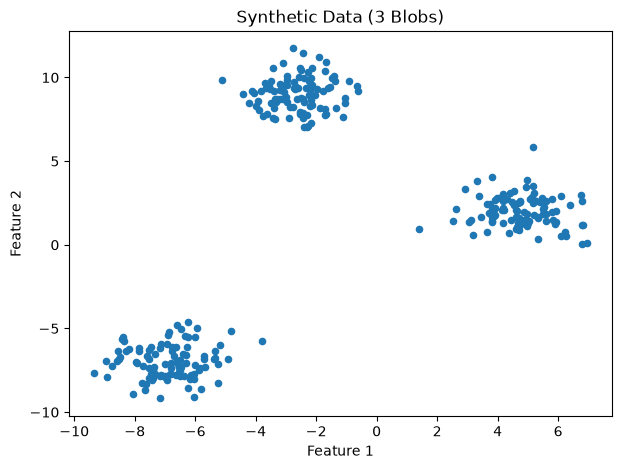

In [3]:
X_blobs, y_blobs = make_blobs(
    n_samples=300,
    centers=3,
    cluster_std=1.0,
    random_state=42
)

plt.figure(figsize=(7, 5))
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], s=20)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Synthetic Data (3 Blobs)")
plt.show()

## 4. Part III – Training K-Means on Synthetic Data

In [4]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X_blobs)

print("Cluster centers:\n", kmeans.cluster_centers_)
cluster_labels = kmeans.predict(X_blobs)
print("First 20 assignments:", cluster_labels[:20])

Cluster centers:
 [[-2.63323268  9.04356978]
 [-6.88387179 -6.98398415]
 [ 4.74710337  2.01059427]]
First 20 assignments: [1 1 0 2 1 2 0 2 0 0 0 2 0 0 1 0 1 2 0 0]


## 5. Part IV – Visualizing Clusters & Decision Boundaries

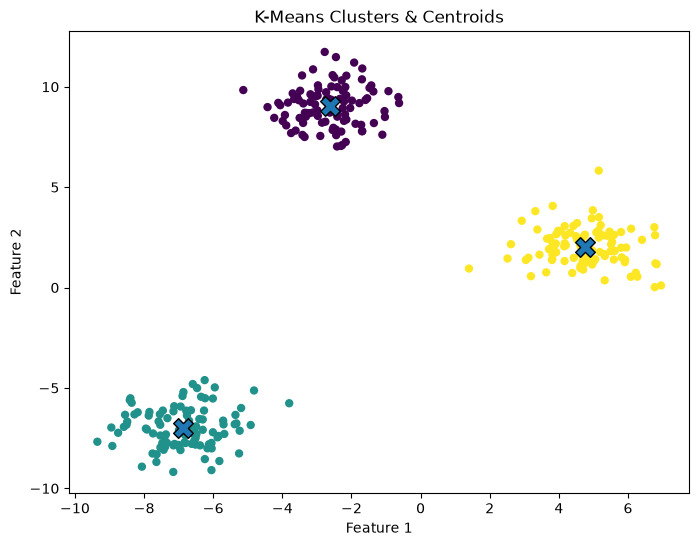

In [5]:
# Plot scatter and centroids
plt.figure(figsize=(8, 6))
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], c=cluster_labels, s=25)
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X", s=200, edgecolor="black"
)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Clusters & Centroids")
plt.show()

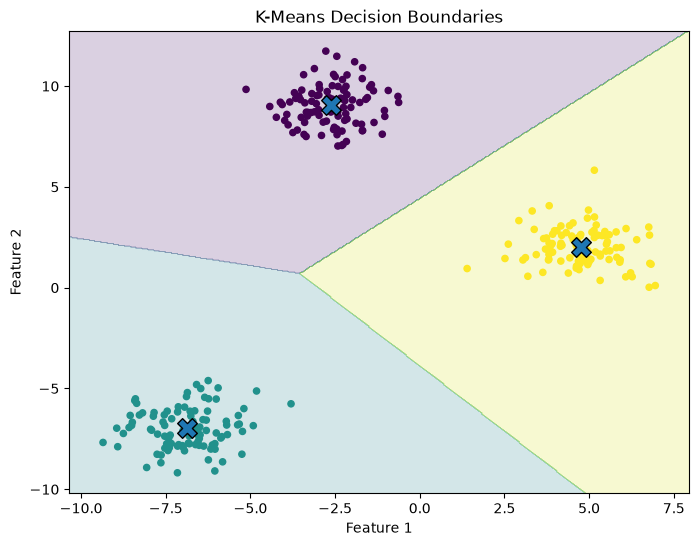

In [6]:
# Plot Decision Boundaries
x_min, x_max = X_blobs[:, 0].min() - 1, X_blobs[:, 0].max() + 1
y_min, y_max = X_blobs[:, 1].min() - 1, X_blobs[:, 1].max() + 1
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)
Z = kmeans.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.2)
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], c=cluster_labels, s=20)
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X", s=200, edgecolor="black"
)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Decision Boundaries")
plt.show()

## 6. Parts V & VI – Evaluation & Random Initializations

In [7]:
print(f"Inertia (n_init=10): {kmeans.inertia_:.2f}")

# Compare initializations
for seed in [0, 1, 2, 3, 4]:
    model = KMeans(n_clusters=3, random_state=seed, n_init=1)
    model.fit(X_blobs)
    print(f"Random state {seed} - Inertia: {model.inertia_:.2f}")

Inertia (n_init=10): 566.86
Random state 0 - Inertia: 566.86
Random state 1 - Inertia: 566.86
Random state 2 - Inertia: 566.86
Random state 3 - Inertia: 566.86
Random state 4 - Inertia: 566.86


## 7. Part VII – Mini-Batch K-Means

In [8]:
mini_batch_kmeans = MiniBatchKMeans(
    n_clusters=3,
    random_state=42,
    batch_size=50,
    n_init=10
)
mini_batch_kmeans.fit(X_blobs)

print(f"Standard K-Means Inertia:   {kmeans.inertia_:.2f}")
print(f"Mini-Batch K-Means Inertia: {mini_batch_kmeans.inertia_:.2f}")

Standard K-Means Inertia:   566.86
Mini-Batch K-Means Inertia: 567.65


## 8. Part VIII – Finding Optimal Clusters (Elbow Method)

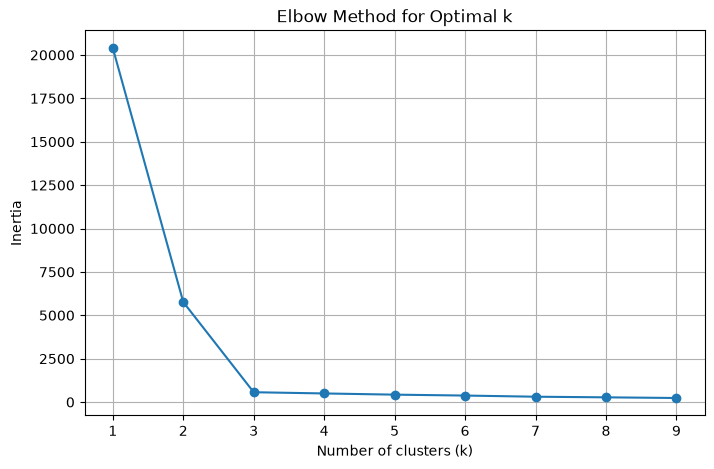

In [9]:
inertias = []
k_range = range(1, 10)
for k in k_range:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_blobs)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range, inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.xticks(k_range)
plt.grid(True)
plt.show()

## 9. Part IX – Applying K-Means to the Iris Dataset

In [10]:
# Fit K-Means on full Iris features
iris_kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
iris_kmeans.fit(X)
iris_clusters = iris_kmeans.labels_

print(f"Iris Clustering Inertia: {iris_kmeans.inertia_:.2f}")

Iris Clustering Inertia: 78.85


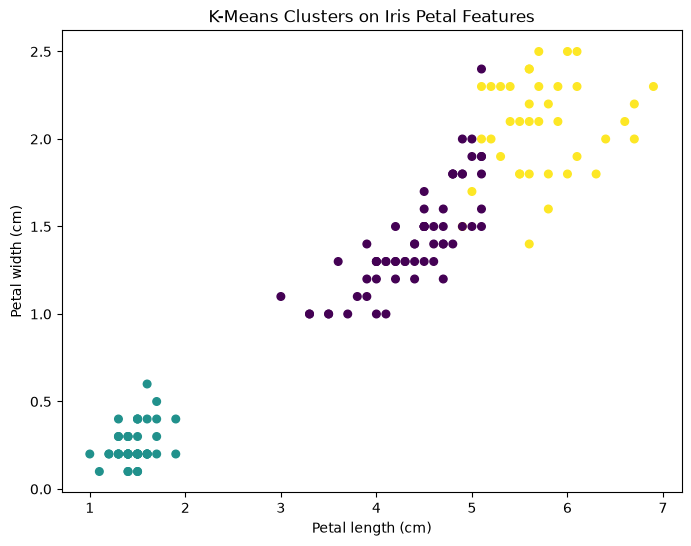

In [11]:


# Scatter plot on Petal Length vs Petal Width
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 2], X[:, 3], c=iris_clusters, s=30)
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("K-Means Clusters on Iris Petal Features")
plt.show()



In [12]:
# Contingency Matrix comparison with actual labels
print("=== CONTINGENCY MATRIX (Clusters vs Species) ===")
print(confusion_matrix(iris_clusters, y))

=== CONTINGENCY MATRIX (Clusters vs Species) ===
[[ 0 48 14]
 [50  0  0]
 [ 0  2 36]]
